In [1]:
# ============================================================
# CELL 1 ─ Install dependencies
# ============================================================
!pip install -q diffusers transformers accelerate gradio pillow

print("✅ All packages installed")

✅ All packages installed


In [2]:
# ============================================================
# CELL 2 ─ Imports & GPU check
# ============================================================
import torch
from diffusers import AutoPipelineForText2Image
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype  = torch.float16 if device.type == "cuda" else torch.float32

print(f"🖥️  Device : {device}")
if device.type == "cuda":
    print(f"   GPU    : {torch.cuda.get_device_name(0)}")
else:
    print("   ⚠️ No GPU detected — generation will work but be slower (~30-60s per image instead of ~1-4s)")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


🖥️  Device : cuda
   GPU    : Tesla T4


In [3]:
# ============================================================
# CELL 3 ─ Load pretrained model (SD-Turbo — fast, distilled Stable Diffusion)
# ============================================================
# SD-Turbo generates a full image in a SINGLE diffusion step (vs ~20-50 for
# regular Stable Diffusion), so it's both fast AND high quality, since it's
# pretrained on a massive image-text dataset — not trained from scratch here.

print("⬇️  Loading SD-Turbo pipeline (one-time download, ~2.5 GB)…")
pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device.type == "cuda" else None,
)
pipe = pipe.to(device)

print("✅ Model loaded and ready")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


⬇️  Loading SD-Turbo pipeline (one-time download, ~2.5 GB)…


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


✅ Model loaded and ready


In [8]:
# ============================================================
# CELL 4 ─ Inference function
# ============================================================

def generate_images(prompt: str, n_images: int = 4, steps: int = 1, seed: int | None = None):
    """
    Generate n_images from a text prompt using SD-Turbo.

    Args:
        prompt   : natural-language text description
        n_images : how many images to generate
        steps    : diffusion steps (1 is the SD-Turbo default & fastest; try 2-4 for slightly more detail)
        seed     : optional int for reproducibility
    """
    generator = torch.Generator(device=device)
    if seed is not None:
        generator = generator.manual_seed(seed)

    images = pipe(
        prompt=[prompt] * n_images,
        num_inference_steps=steps,
        guidance_scale=0.0,   # SD-Turbo is distilled for guidance_scale=0
        generator=generator,
    ).images
    return images


def display_inference(prompt: str, n: int = 4, steps: int = 1, seed: int | None = 42):
    imgs = generate_images(prompt, n_images=n, steps=steps, seed=seed)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.5))
    if n == 1:
        axes = [axes]
    for ax, img in zip(axes, imgs):
        ax.imshow(img)
        ax.axis("off")
    fig.suptitle(f'Prompt: "{prompt}"', fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
    return imgs


print("✅ Inference function ready")
print("   Usage: display_inference('a golden retriever running on a beach', n=4)")

✅ Inference function ready
   Usage: display_inference('a golden retriever running on a beach', n=4)


  0%|          | 0/1 [00:00<?, ?it/s]

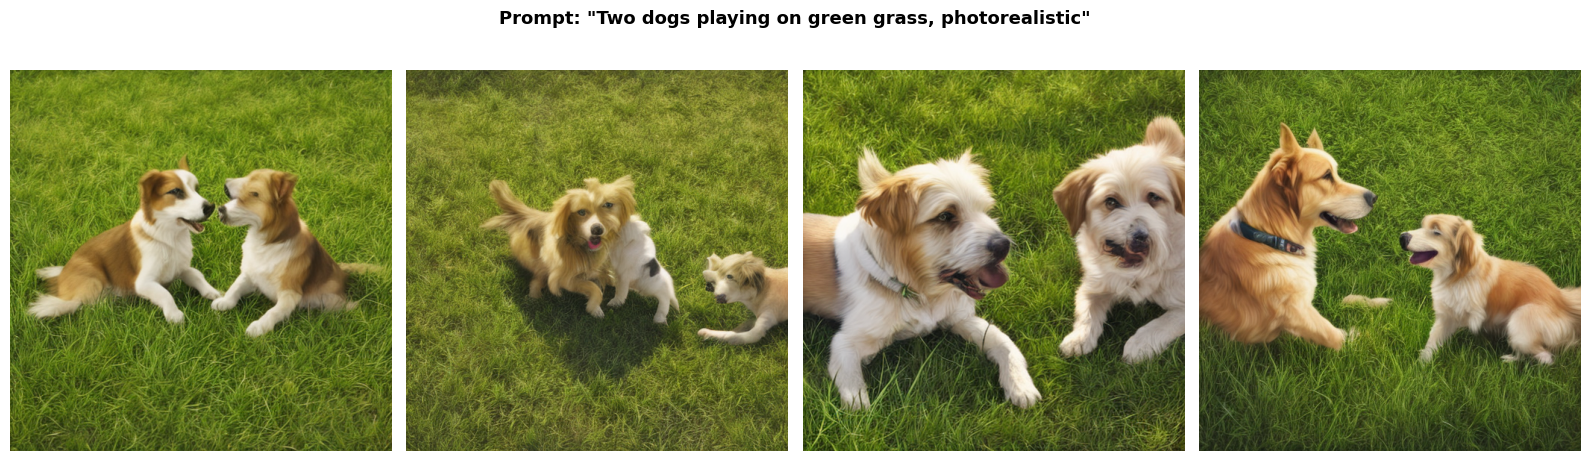

  0%|          | 0/1 [00:00<?, ?it/s]

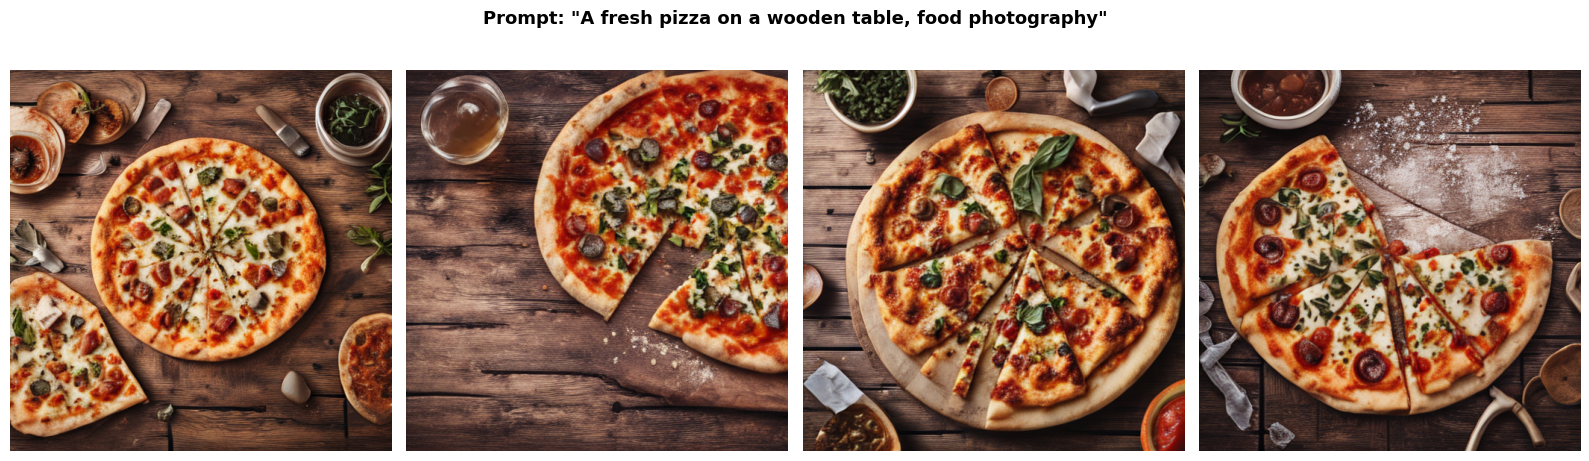

  0%|          | 0/1 [00:00<?, ?it/s]

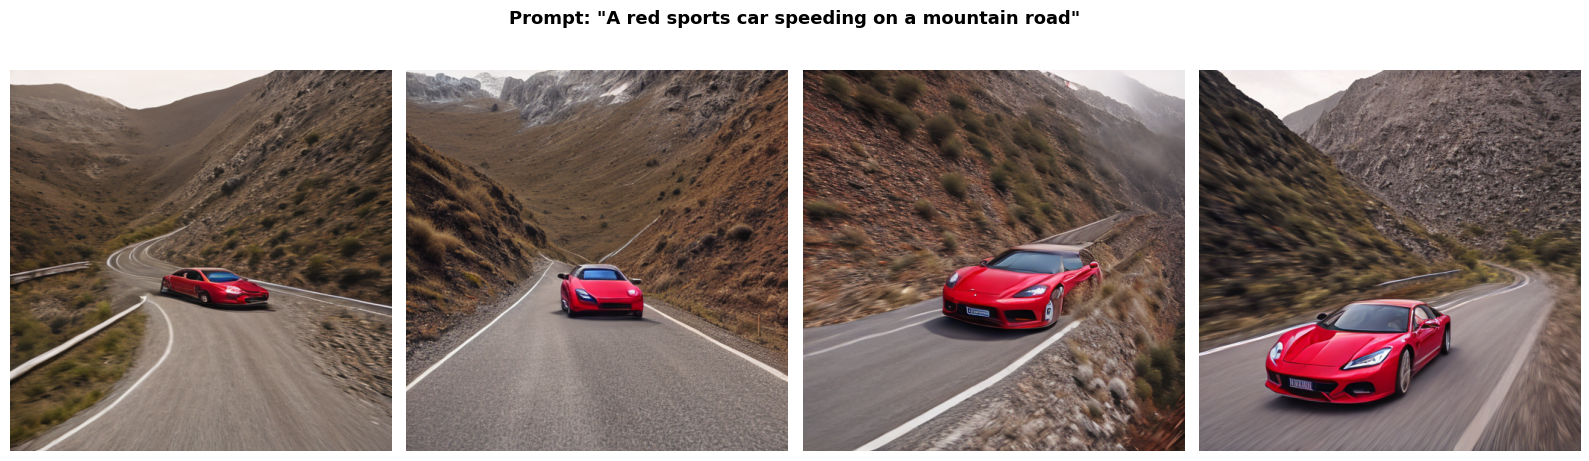

  0%|          | 0/1 [00:00<?, ?it/s]

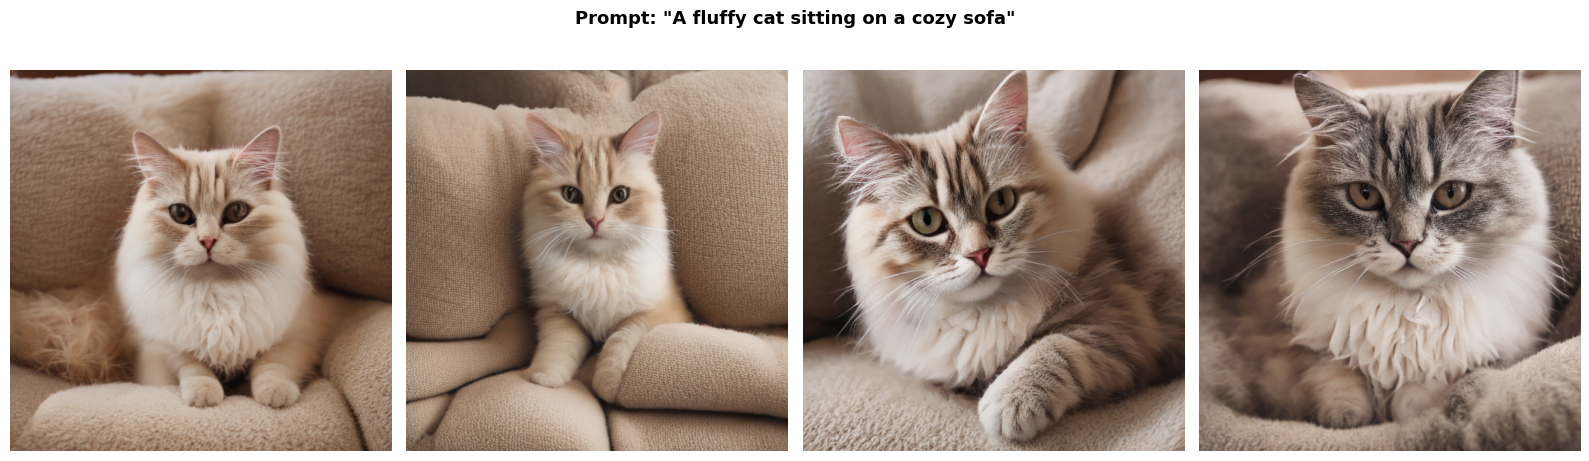

In [5]:
# ============================================================
# CELL 5 ─ Demo on various prompts
# ============================================================
prompts = [
    "Two dogs playing on green grass, photorealistic",
    "A fresh pizza on a wooden table, food photography",
    "A red sports car speeding on a mountain road",
    "A fluffy cat sitting on a cozy sofa",
]

for p in prompts:
    display_inference(p, n=4, seed=42)

In [6]:
# ============================================================
# CELL 6 ─ Gradio Web UI
# ============================================================
import gradio as gr

_gallery_history = []

def gradio_generate(prompt, n_images, steps, seed_val):
    seed = int(seed_val) if seed_val else None
    imgs = generate_images(prompt, n_images=int(n_images), steps=int(steps), seed=seed)
    for img in imgs:
        _gallery_history.append((img, prompt))
    return imgs, _gallery_history[-20:]


with gr.Blocks(title="🎨 Text-to-Image (SD-Turbo)", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🎨 Text-to-Image Generator (Pretrained SD-Turbo)")
    gr.Markdown("Type any prompt — generates real, high-quality images in seconds. No training required.")

    with gr.Row():
        with gr.Column(scale=3):
            prompt_box = gr.Textbox(label="Text Prompt", placeholder="A golden retriever playing on a sunny beach…", lines=2)
            with gr.Row():
                n_slider = gr.Slider(1, 8, value=4, step=1, label="Number of images")
                steps_slider = gr.Slider(1, 4, value=1, step=1, label="Diffusion steps (1 = fastest)")
            seed_box = gr.Number(label="Seed (blank = random)", precision=0)
            btn = gr.Button("🖌️ Generate", variant="primary")
        with gr.Column(scale=5):
            output_gallery = gr.Gallery(label="Generated Images", columns=4, height=300)

    gr.Markdown("### 📜 Generation History")
    history_gallery = gr.Gallery(label="History (last 20)", columns=5, height=250)

    btn.click(gradio_generate,
              inputs=[prompt_box, n_slider, steps_slider, seed_box],
              outputs=[output_gallery, history_gallery])

demo.launch(share=True, debug=False)

/tmp/ipykernel_4092/525499865.py:16: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="🎨 Text-to-Image (SD-Turbo)", theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f77043ff93e3527d71.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [7]:
#SD-Turbo uses Adversarial Diffusion Distillation — a GAN-based discriminator was used during its training to ensure sharp, realistic outputs in a single step. This is more advanced than a standard GAN pipeline